# Explainable GeoAI Demo for Urban Accessibility

This notebook is a **public portfolio demonstration** using synthetic, non-sensitive data.

It illustrates how social and spatial predictors can be combined with geographically structured validation to model experienced accessibility to urban services. It does not contain raw dissertation data.


## 1. Imports


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

pd.set_option("display.max_columns", None)


## 2. Load the synthetic dataset


In [2]:
DATA_PATH = Path("../data/synthetic_accessibility_demo.csv")
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()


Shape: (220, 12)


,district,gender_indicator,caregiving,mobility_limitation,income_index,safety_score,mobility_score,service_quality,nearest_service_m,opportunity_1000m,potential_access_index,experienced_access
0,1,0,0,0,0.832,2.530,3.324,3.408,768.0,38.8,62.56,5.000
1,1,1,0,0,0.485,3.209,3.102,4.496,553.7,15.8,37.15,4.766
2,1,1,0,0,0.381,2.976,3.226,4.155,1162.8,19.7,20.92,4.721
3,1,0,0,0,0.469,2.439,3.456,3.333,289.4,29.5,66.37,4.828
4,1,0,0,0,0.631,4.737,3.732,3.988,940.0,27.8,42.22,5.000


## 3. Define predictors and target


In [3]:
predictors = [
    "gender_indicator",
    "caregiving",
    "mobility_limitation",
    "income_index",
    "safety_score",
    "mobility_score",
    "service_quality",
    "nearest_service_m",
    "opportunity_1000m",
    "potential_access_index",
]

X = df[predictors]
y = df["experienced_access"]
groups = df["district"]
X.describe().T


,count,mean,std,min,25%,50%,75%,max
gender_indicator,220.0,0.500000,0.501140,0.000,0.00000,0.5000,1.00000,1.00
caregiving,220.0,0.177273,0.382770,0.000,0.00000,0.0000,0.00000,1.00
mobility_limitation,220.0,0.122727,0.328872,0.000,0.00000,0.0000,0.00000,1.00
income_index,220.0,0.525255,0.182039,0.088,0.38950,0.5210,0.64925,0.95
safety_score,220.0,3.197891,0.753051,1.000,2.73200,3.2225,3.62325,5.00
mobility_score,220.0,3.304677,0.650293,1.584,2.91750,3.3170,3.73250,5.00
service_quality,220.0,3.490150,0.686969,1.636,3.06175,3.5045,3.95750,5.00
nearest_service_m,220.0,635.663182,241.241689,100.000,480.45000,640.1500,780.40000,1320.30
opportunity_1000m,220.0,26.580000,9.940823,3.600,20.27500,26.8500,33.02500,56.10
potential_access_index,220.0,49.368500,16.299857,7.610,37.96500,49.5250,60.89500,98.90


## 4. District-held-out cross-validation

`GroupKFold` prevents observations from the same district from appearing in both the training and validation fold.


In [4]:
model = GradientBoostingRegressor(random_state=42)
cv = GroupKFold(n_splits=5)

oof_pred = cross_val_predict(
    model,
    X,
    y,
    groups=groups,
    cv=cv
)

r2 = r2_score(y, oof_pred)
mae = mean_absolute_error(y, oof_pred)
rmse = mean_squared_error(y, oof_pred) ** 0.5

print(f"OOF R²:   {r2:.3f}")
print(f"OOF MAE:  {mae:.3f}")
print(f"OOF RMSE: {rmse:.3f}")


OOF R²:   0.186
OOF MAE:  0.236
OOF RMSE: 0.298


## 5. Observed vs predicted accessibility


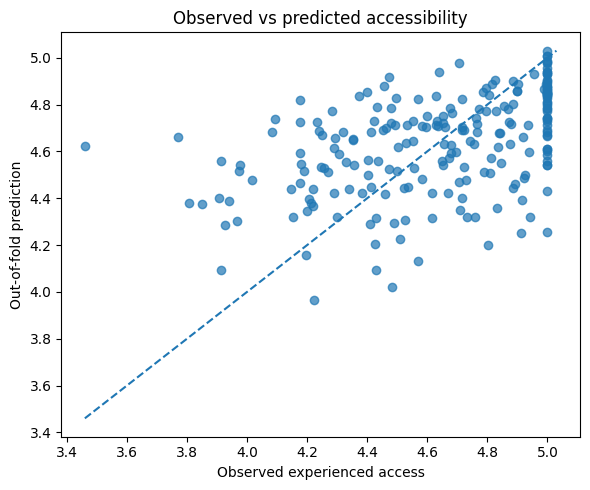

In [5]:
plt.figure(figsize=(6, 5))
plt.scatter(y, oof_pred, alpha=0.7)
lims = [min(y.min(), oof_pred.min()), max(y.max(), oof_pred.max())]
plt.plot(lims, lims, linestyle="--")
plt.xlabel("Observed experienced access")
plt.ylabel("Out-of-fold prediction")
plt.title("Observed vs predicted accessibility")
plt.tight_layout()
plt.show()


## 6. Fit the final model and inspect feature importance


In [6]:
model.fit(X, y)

importance = (
    pd.Series(model.feature_importances_, index=predictors)
    .sort_values(ascending=False)
)

importance


service_quality           0.196394
mobility_score            0.181255
safety_score              0.177757
income_index              0.132678
potential_access_index    0.117419
nearest_service_m         0.055221
opportunity_1000m         0.044787
mobility_limitation       0.040071
caregiving                0.037145
gender_indicator          0.017273
dtype: float64

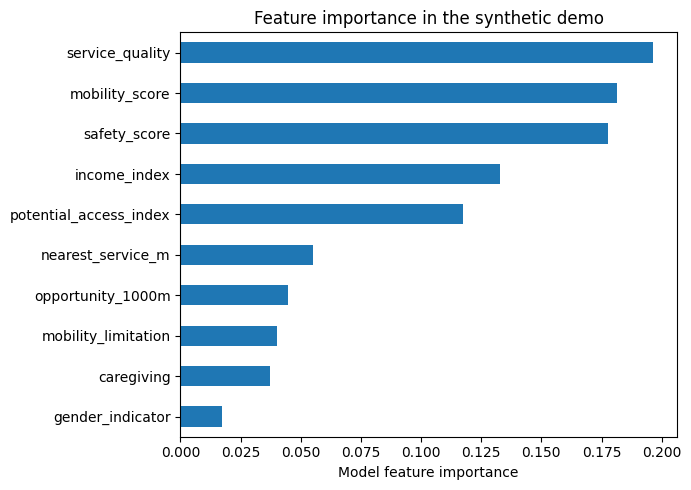

In [7]:
plt.figure(figsize=(7, 5))
importance.sort_values().plot(kind="barh")
plt.xlabel("Model feature importance")
plt.title("Feature importance in the synthetic demo")
plt.tight_layout()
plt.show()


## 7. Optional SHAP explanation

If `shap` is installed, this section calculates SHAP values for the fitted model.


c:\Users\Fereshteh\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Background dataset has 220 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=220 when initializing the masker.


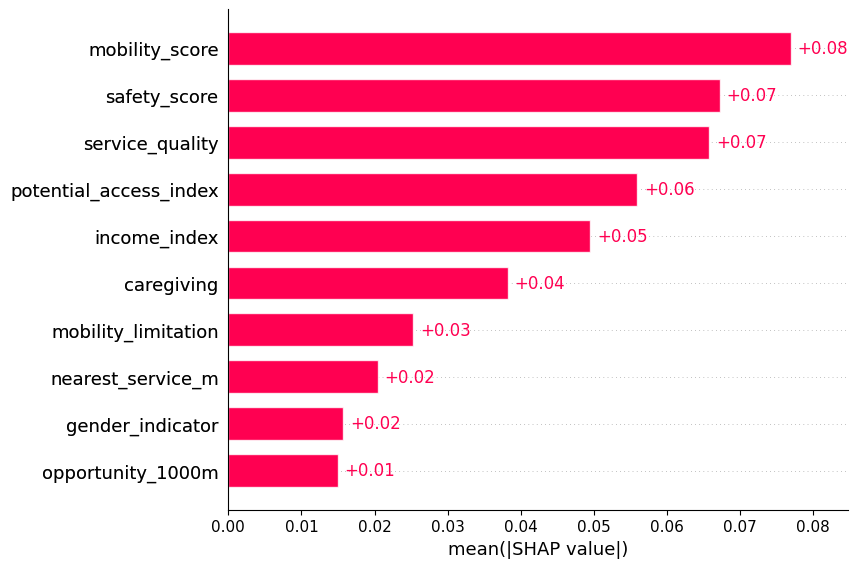

In [8]:
try:
    import shap

    explainer = shap.Explainer(model, X)
    shap_values = explainer(X)
    shap.plots.bar(shap_values, max_display=10)
except ImportError:
    print("SHAP is not installed. Run: pip install shap")
except Exception as exc:
    print("SHAP could not run in this environment:", exc)


## Interpretation note

This notebook demonstrates a reproducible workflow rather than a substantive empirical result. Because the dataset is synthetic, predictive performance and feature importance should not be interpreted as findings about Tehran or any real population.
